### **UNSW-NB15: Machine Learning Model Comparison**
##### Models: Logistic Regression, Random Forest, XGBoost


In [1]:
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

### **1. Configuration**

In [2]:
RANDOM_STATE = 42
TARGET = "label"

DROP_COLUMNS = ["id", "attack_cat", "traffic_type"]

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)


### **2. Load Dataset**

In [3]:
print("\nLoading datasets...")

df_train = pd.read_parquet("../dataset/train_full.parquet")
df_test = pd.read_parquet("../dataset/test_full.parquet")

print("Training shape:", df_train.shape)
print("Testing shape :", df_test.shape)


Loading datasets...
Training shape: (175341, 45)
Testing shape : (82332, 45)


### **3. Separate Features and Target**

In [5]:
# Drop only columns that actually exist
DROP_COLUMNS = ["id", "attack_cat", "traffic_type"]

columns_to_drop = [
    col for col in DROP_COLUMNS
    if col in df_train.columns
]

X_train = df_train.drop(columns=columns_to_drop + [TARGET])
y_train = df_train[TARGET]

X_test = df_test.drop(columns=columns_to_drop + [TARGET])
y_test = df_test[TARGET]

### **4. Identify Numerical and Categorical Features**

In [6]:
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))


Numerical features: 39
Categorical features: 3


C:\Users\Prateek\AppData\Local\Temp\ipykernel_72636\3187327844.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


### **5. Preprocessing Pipelines**

In [7]:
# Logistic Regression preprocessing
lr_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

# Tree-based model preprocessing
tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(strategy="median"),
            numerical_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

### **6. Define Models**

In [8]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", lr_preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", tree_preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", tree_preprocessor),
        ("model", XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

### **7. Train and Evaluate Models**

In [9]:
results = []
trained_models = {}

for model_name, model in models.items():

    print("\n" + "=" * 60)
    print("Training:", model_name)
    print("=" * 60)

    start_time = time.time()

    # Train
    model.fit(X_train, y_train)

    training_time = time.time() - start_time

    # Predict
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    # Store results
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "Training Time (sec)": training_time,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

    trained_models[model_name] = model

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print(f"\nTraining Time: {training_time:.2f} seconds")



Training: Logistic Regression


c:\PK\Projects\network-intrusion\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)



Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.61      0.74     37000
           1       0.75      0.97      0.85     45332

    accuracy                           0.81     82332
   macro avg       0.85      0.79      0.80     82332
weighted avg       0.84      0.81      0.80     82332


Confusion Matrix:
[[22579 14421]
 [ 1249 44083]]

Training Time: 5.37 seconds

Training: Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.73      0.84     37000
           1       0.82      0.99      0.89     45332

    accuracy                           0.87     82332
   macro avg       0.90      0.86      0.86     82332
weighted avg       0.89      0.87      0.87     82332


Confusion Matrix:
[[26975 10025]
 [  629 44703]]

Training Time: 376.19 seconds

Training: XGBoost

Classification Report:
              precision    recall  f1-score   support

           0   

### **8. Model Comparison Table**

In [10]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    os.path.join(RESULTS_DIR, "model_comparison.csv"),
    index=False
)


FINAL MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC  Training Time (sec)    TN    FP   FN    TP
            XGBoost    0.8755     0.8232  0.9856    0.8971   0.9844  0.9885              13.2556 27403  9597  651 44681
      Random Forest    0.8706     0.8168  0.9861    0.8935   0.9794  0.9835             376.1880 26975 10025  629 44703
Logistic Regression    0.8097     0.7535  0.9724    0.8491   0.9556  0.9661               5.3721 22579 14421 1249 44083


### **9. Visualize Performance Metrics**

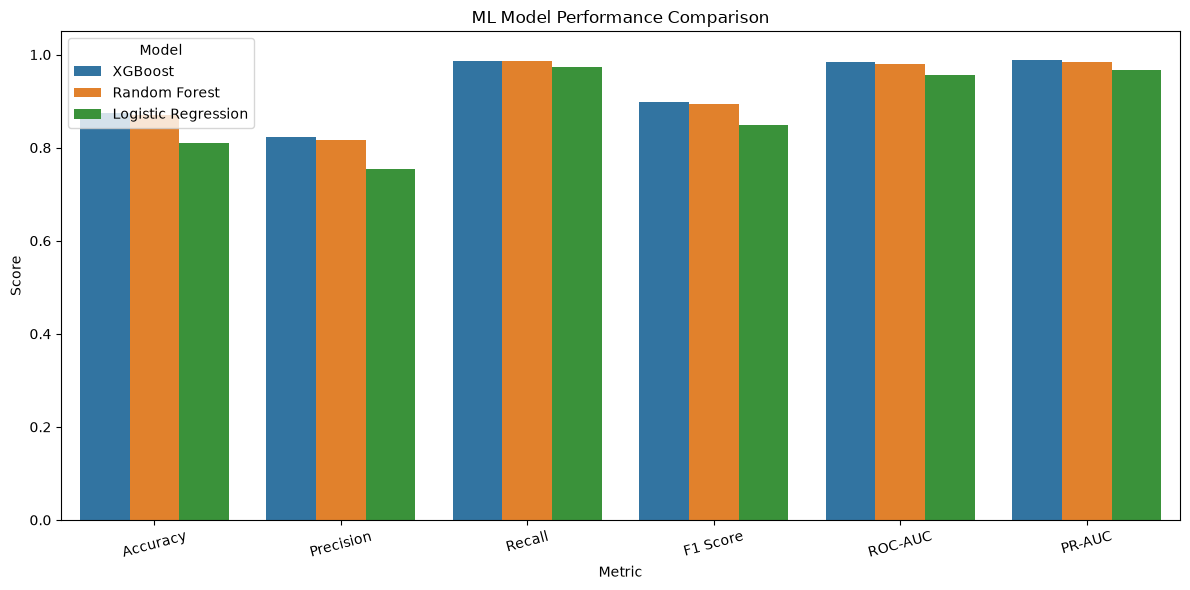

In [11]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "PR-AUC"
]

plot_df = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("ML Model Performance Comparison")
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "model_comparison.png"),
    dpi=300
)

plt.show()


### **10. Confusion Matrix Visualizations**

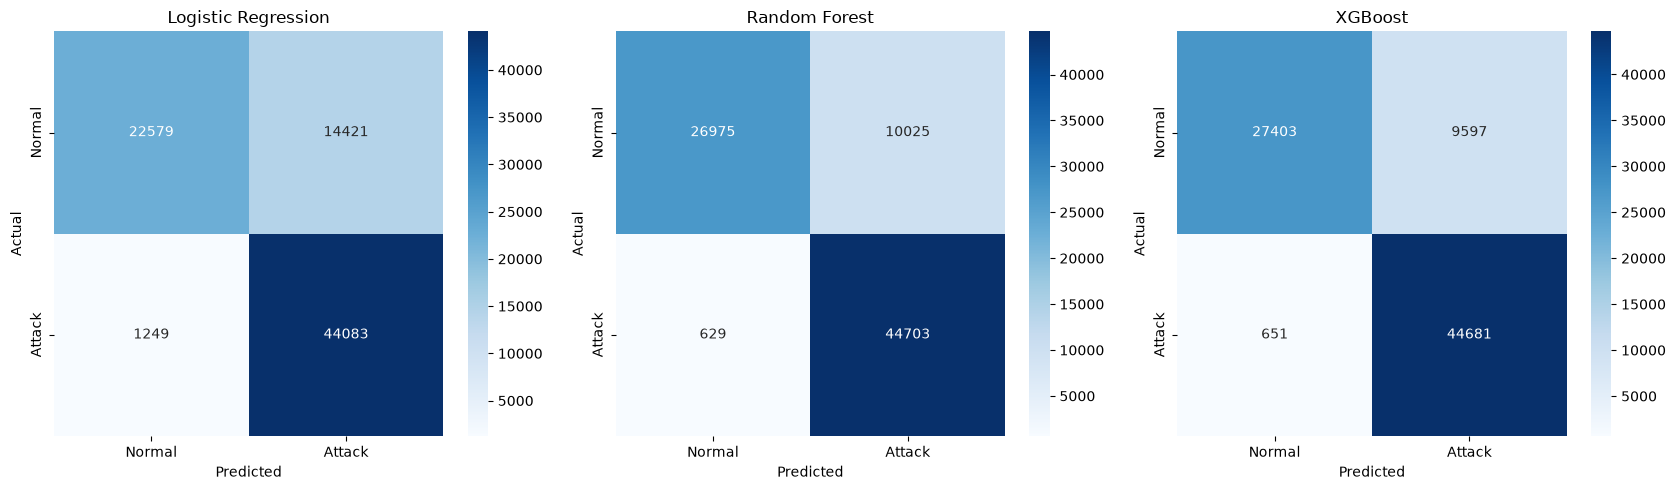

In [12]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

for ax, (model_name, model) in zip(axes, trained_models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["Normal", "Attack"],
        yticklabels=["Normal", "Attack"]
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "confusion_matrices.png"),
    dpi=300
)

plt.show()


### **11. Best Model Summary**

In [13]:
best_model_name = results_df.iloc[0]["Model"]

print("\n" + "=" * 60)
print("MODEL COMPARISON COMPLETED")
print("=" * 60)

print("Best model based on F1 Score:", best_model_name)

print("\nSaved files:")
print("- model_comparison.csv")
print("- model_comparison.png")
print("- confusion_matrices.png")
print("- Trained model files (.joblib)")

print("\nAll results saved inside:", RESULTS_DIR)



MODEL COMPARISON COMPLETED
Best model based on F1 Score: XGBoost

Saved files:
- model_comparison.csv
- model_comparison.png
- confusion_matrices.png
- Trained model files (.joblib)

All results saved inside: results
